In [1]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
import kagglehub

# télécharger la dernière version
path = kagglehub.dataset_download("shivamb/netflix-shows")

print("Path to dataset files:", path)

c:\Users\Yannis\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Yannis\.cache\kagglehub\datasets\shivamb\netflix-shows\versions\5


In [3]:
import pandas as pd

# Charger le dataset téléchargé via KaggleHub
file_path = path + "/netflix_titles.csv"
df = pd.read_csv(file_path)

# Garder les colonnes utiles 
df = df[['type','country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']]

# Gérer les valeurs manquantes
df = df.fillna('Inconnu')

# Créer une colonne "année de sortie" à partir de la date
df['année_de_sortie'] = df['date_added'].apply(
    lambda x: int(x[-4:]) if isinstance(x, str) and x[-4:].isdigit() else None
)

# Afficher un aperçu pour vérifier
print(df.head())
print(df.info())

# Sauvegarder le fichier nettoyé
df.to_csv("netflix_clean.csv", index=False)
print("Fichier nettoyé enregistré sous netflix_clean.csv")


      type        country          date_added  release_year rating   duration  \
0    Movie  United States  September 25, 2021          2020  PG-13     90 min   
1  TV Show   South Africa  September 24, 2021          2021  TV-MA  2 Seasons   
2  TV Show        Inconnu  September 24, 2021          2021  TV-MA   1 Season   
3  TV Show        Inconnu  September 24, 2021          2021  TV-MA   1 Season   
4  TV Show          India  September 24, 2021          2021  TV-MA  2 Seasons   

                                           listed_in  année_de_sortie  
0                                      Documentaries           2021.0  
1    International TV Shows, TV Dramas, TV Mysteries           2021.0  
2  Crime TV Shows, International TV Shows, TV Act...           2021.0  
3                             Docuseries, Reality TV           2021.0  
4  International TV Shows, Romantic TV Shows, TV ...           2021.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data co

In [4]:
# Nombre de films vs séries
count_type = df['type'].value_counts()
print("\nRépartition des types de contenus :")
print(count_type)


Répartition des types de contenus :
type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [ ]:
# Chargement du fichier
df = pd.read_csv("netflix_clean.csv")

# S'assurer que la colonne 'release_year' est bien numérique
df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')

# Supprimer les valeurs manquantes ou aberrantes (avant 1900 par ex)
df = df[df['release_year'].between(1900, 2025)]

# Compter le nombre de contenus par année
count_year = df['release_year'].value_counts().sort_index()

# Afficher toute la distribution sans coupure
pd.set_option('display.max_rows', None)

print("Répartition des contenus par année de sortie :\n")
print(count_year)


Répartition des contenus par année de sortie :

release_year
1925       1
1942       2
1943       3
1944       3
1945       4
1946       2
1947       1
1954       2
1955       3
1956       2
1958       3
1959       1
1960       4
1961       1
1962       3
1963       2
1964       2
1965       2
1966       1
1967       5
1968       3
1969       2
1970       2
1971       5
1972       5
1973      10
1974       7
1975       7
1976       9
1977       7
1978       7
1979      11
1980      11
1981      13
1982      17
1983      11
1984      12
1985      10
1986      13
1987       8
1988      18
1989      16
1990      22
1991      17
1992      23
1993      28
1994      22
1995      25
1996      24
1997      38
1998      36
1999      39
2000      37
2001      45
2002      51
2003      61
2004      64
2005      80
2006      96
2007      88
2008     136
2009     152
2010     194
2011     185
2012     237
2013     288
2014     352
2015     560
2016     902
2017    1032
2018    1147
2019    1030
202

In [ ]:
# Charger le fichier nettoyé
df = pd.read_csv("netflix_clean.csv")

# S'assurer que 'release_year' est bien numérique
df['release_year'] = pd.to_numeric(df['release_year'], errors='coerce')

# Filtrer l'année 2018
nb_2018 = df[df['release_year'] == 2018].shape[0]

print(f"Nombre de contenus sortis en 2018 : {nb_2018}")


Nombre de contenus sortis en 2018 : 1147


In [ ]:
# Genres les plus représentés
# La colonne 'listed_in' contient les genres séparés par des virgules
# On les découpe, on les met dans une liste, puis on compte les occurrences
all_genres = df['listed_in'].dropna().str.split(', ')
genres = [g for sublist in all_genres for g in sublist]
genres_count = pd.Series(genres).value_counts()

print("\nTop 10 genres les plus représentés :")
print(genres_count)


Top 10 genres les plus représentés :
International Movies            2752
Dramas                          2427
Comedies                        1674
International TV Shows          1351
Documentaries                    869
Action & Adventure               859
TV Dramas                        763
Independent Movies               756
Children & Family Movies         641
Romantic Movies                  616
TV Comedies                      581
Thrillers                        577
Crime TV Shows                   470
Kids' TV                         451
Docuseries                       395
Music & Musicals                 375
Romantic TV Shows                370
Horror Movies                    357
Stand-Up Comedy                  343
Reality TV                       255
British TV Shows                 253
Sci-Fi & Fantasy                 243
Sports Movies                    219
Anime Series                     176
Spanish-Language TV Shows        174
TV Action & Adventure            168


C:\Users\Yannis\AppData\Local\Temp\ipykernel_44972\1164095690.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set1')


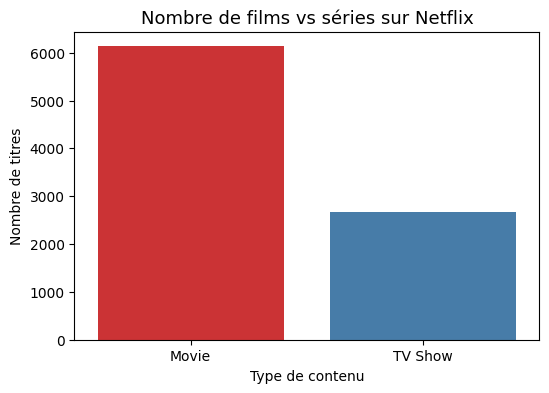

In [7]:
# Countplot - Comparaison Films vs Séries
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='type', palette='Set1')
plt.title("Nombre de films vs séries sur Netflix", fontsize=13)
plt.xlabel("Type de contenu")
plt.ylabel("Nombre de titres")
plt.show()

In [8]:
# Supprimer les lignes sans pays valide
df_pays = df['country'].replace('Inconnu', pd.NA).dropna()

# Séparer les pays multiples (ex: "France, Belgium")
df_pays = df_pays.str.split(',').explode().str.strip()

# Compter les occurrences de chaque pays
top_pays = df_pays.value_counts().head(10)

# Afficher le résultat
print("Top 10 des pays producteurs (en excluant 'Inconnu') :\n")
print(top_pays)


Top 10 des pays producteurs (en excluant 'Inconnu') :

country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


C:\Users\Yannis\AppData\Local\Temp\ipykernel_44972\141522365.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_pays.values, y=top_pays.index, palette="coolwarm")


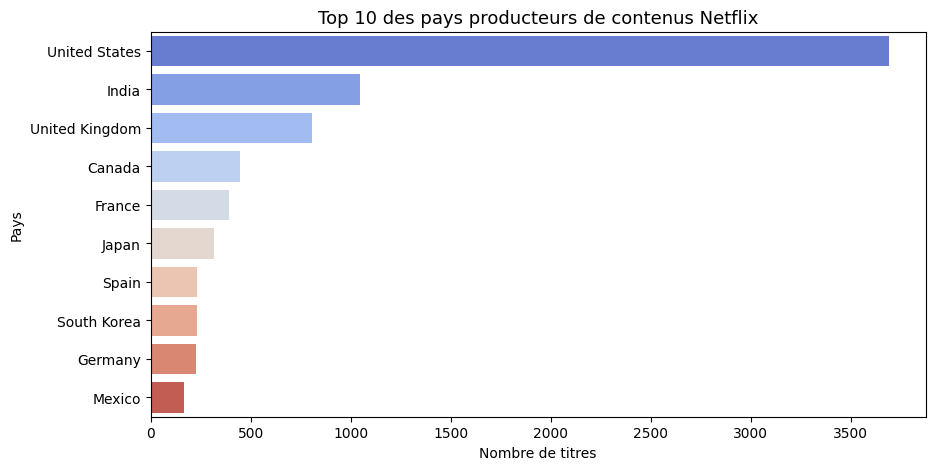

In [9]:
# Barplot - Top 10 pays producteurs
plt.figure(figsize=(10,5))
sns.barplot(x=top_pays.values, y=top_pays.index, palette="coolwarm")
plt.title("Top 10 des pays producteurs de contenus Netflix", fontsize=13)
plt.xlabel("Nombre de titres")
plt.ylabel("Pays")
plt.show()

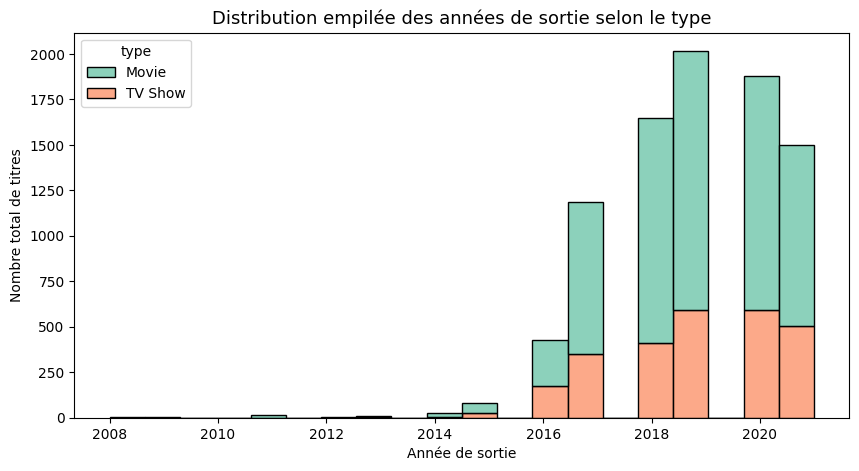

In [ ]:
# histplot - Distribution des années de sortie
plt.figure(figsize=(10,5))
sns.histplot(
    data=df,
    x='année_de_sortie',
    hue='type',
    bins=20,
    kde=False,
    multiple='stack',   
    palette='Set2'
)
plt.title("Distribution empilée des années de sortie selon le type", fontsize=13)
plt.xlabel("Année de sortie")
plt.ylabel("Nombre total de titres")
plt.show()




Matrice de corrélation :

                 release_year  année_de_sortie  duree_numerique
release_year         1.000000         0.111548        -0.249925
année_de_sortie      0.111548         1.000000         0.029345
duree_numerique     -0.249925         0.029345         1.000000


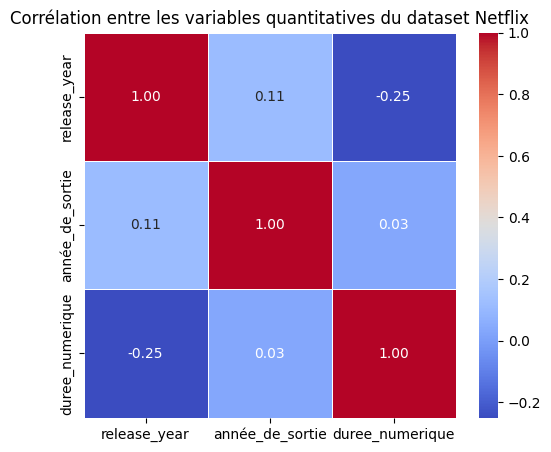

In [ ]:
# Charger le fichier nettoyé
df = pd.read_csv("netflix_clean.csv")

# Préparation des variables quantitatives 

# Convertir la durée en nombre (ex : "90 min" → 90, "3 Seasons" → 3)
def convertir_duree(x):
    if isinstance(x, str):
        if "min" in x:
            return int(x.replace(" min", ""))
        elif "Season" in x:
            return int(x.split(" ")[0])
    return None

df["duree_numerique"] = df["duration"].apply(convertir_duree)

# Sélectionner uniquement les colonnes numériques pertinentes
colonnes_quanti = ["release_year", "année_de_sortie", "duree_numerique"]
df_quanti = df[colonnes_quanti].dropna()

# Matrice de corrélation 
corr = df_quanti.corr()

print("Matrice de corrélation :\n")
print(corr)

# Heatmap 
plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Corrélation entre les variables quantitatives du dataset Netflix")
plt.show()


C:\Users\Yannis\AppData\Local\Temp\ipykernel_44972\36906348.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="type", y="duree_numerique", palette="pastel")


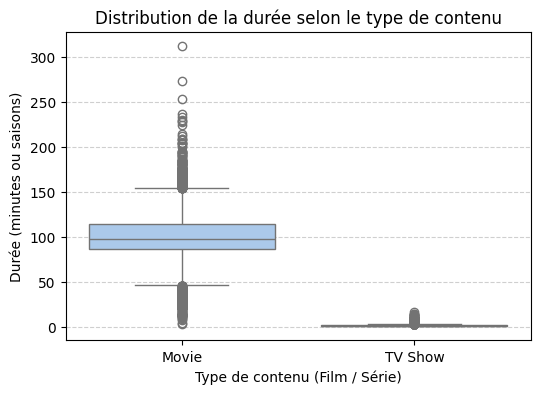

In [ ]:
# Charger le fichier nettoyé
df = pd.read_csv("netflix_clean.csv")

# Conversion de la durée en valeur numérique 
def convertir_duree(x):
    if isinstance(x, str):
        if "min" in x:
            return int(x.replace(" min", ""))
        elif "Season" in x:
            return int(x.split(" ")[0])
    return None

df["duree_numerique"] = df["duration"].apply(convertir_duree)

# Création du boxplot 
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="type", y="duree_numerique", palette="pastel")
plt.title("Distribution de la durée selon le type de contenu")
plt.xlabel("Type de contenu (Film / Série)")
plt.ylabel("Durée (minutes ou saisons)")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()
